# Customer segmentation using KNN

#### Importing Libraries

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
import pandas as pd
import matplotlib.ticker as ticker
from sklearn import preprocessing
%matplotlib inline

Download dataset from 
https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/ML0101ENv3/labs/teleCust1000t.csv

#### Reading CSV file

In [2]:
df = pd.read_csv('teleCust1000t.csv')
df.head()

,region,tenure,age,marital,address,income,ed,employ,retire,gender,reside,custcat
0,2,13,44,1,9,64.0,4,5,0.0,0,2,1
1,3,11,33,1,7,136.0,5,5,0.0,0,6,4
2,3,68,52,1,24,116.0,1,29,0.0,1,2,3
3,2,33,33,0,12,33.0,2,0,0.0,1,1,1
4,2,23,30,1,9,30.0,1,2,0.0,0,4,3


#### Checking how many of each class is in our dataset

In [3]:
df['custcat'].value_counts()

3    281
1    266
4    236
2    217
Name: custcat, dtype: int64

#### Lets define feature set X:
To use scikit-learn library, we have to convert the Pandas data frame to a Numpy array:

In [4]:
df.columns

Index(['region', 'tenure', 'age', 'marital', 'address', 'income', 'ed',
       'employ', 'retire', 'gender', 'reside', 'custcat'],
      dtype='object')

In [5]:
X = df[['region', 'tenure', 'age', 'marital', 'address', 'income', 
        'ed', 'employ', 'retire', 'gender', 'reside']].values    #converting into numpy arrays
X[0:5]    #seeing first five rows

array([[  2.,  13.,  44.,   1.,   9.,  64.,   4.,   5.,   0.,   0.,   2.],
       [  3.,  11.,  33.,   1.,   7., 136.,   5.,   5.,   0.,   0.,   6.],
       [  3.,  68.,  52.,   1.,  24., 116.,   1.,  29.,   0.,   1.,   2.],
       [  2.,  33.,  33.,   0.,  12.,  33.,   2.,   0.,   0.,   1.,   1.],
       [  2.,  23.,  30.,   1.,   9.,  30.,   1.,   2.,   0.,   0.,   4.]])

#### Setting y

In [6]:
y = df['custcat'].values
y[0:5]

array([1, 4, 3, 1, 3], dtype=int64)

#### Normalizing Data:

Data Standardization give data zero mean and unit variance, it is good practice, especially for algorithms such as KNN which is based on distance of cases:

In [7]:
X = preprocessing.StandardScaler().fit(X).transform(X)   
#fit->Compute the mean and std to be used for later scaling.
#trasnform->Perform standardization by centering and scaling.
X[0:5]

array([[-0.02696767, -1.055125  ,  0.18450456,  1.0100505 , -0.25303431,
        -0.12650641,  1.0877526 , -0.5941226 , -0.22207644, -1.03459817,
        -0.23065004],
       [ 1.19883553, -1.14880563, -0.69181243,  1.0100505 , -0.4514148 ,
         0.54644972,  1.9062271 , -0.5941226 , -0.22207644, -1.03459817,
         2.55666158],
       [ 1.19883553,  1.52109247,  0.82182601,  1.0100505 ,  1.23481934,
         0.35951747, -1.36767088,  1.78752803, -0.22207644,  0.96655883,
        -0.23065004],
       [-0.02696767, -0.11831864, -0.69181243, -0.9900495 ,  0.04453642,
        -0.41625141, -0.54919639, -1.09029981, -0.22207644,  0.96655883,
        -0.92747794],
       [-0.02696767, -0.58672182, -0.93080797,  1.0100505 , -0.25303431,
        -0.44429125, -1.36767088, -0.89182893, -0.22207644, -1.03459817,
         1.16300577]])

#### Splitting into training and testing dataset

We will use Train/Test Split approach. Train/Test Split involves splitting the dataset into training and testing sets respectively, which are mutually exclusive. After which, we train with the training set and test with the testing set.
This will provide a more accurate evaluation on out-of-sample accuracy because the testing dataset is not part of the dataset that have been used to train the data.

In [8]:
from sklearn.model_selection import train_test_split         #importing library
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=0)    #splitting data into train and test
print ('Train set:', X_train.shape,  y_train.shape)    #for getting shape of training set
print ('Test set:', X_test.shape,  y_test.shape)

Train set: (800, 11) (800,)
Test set: (200, 11) (200,)


### Making Model

In [9]:
from sklearn.neighbors import KNeighborsClassifier    #importing library

#### Training

In [10]:
k = 4    #taking value of k = 4 since there are 4 distinct values for target in dataset 

neg = KNeighborsClassifier(n_neighbors = k).fit(X_train,y_train)    

#### Predicting 

In [11]:
yhat = neg.predict(X_test)    #making predictions on testing dataset 
yhat[0:5]

array([3, 1, 2, 4, 2], dtype=int64)

### Accuracy Evaluation 

For evaluating an algorithm, confusion matrix, precision, recall and f1 score are the most commonly used metrics. We will use confusion matrix for our algorithm.

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
print(confusion_matrix(y_test, yhat))
print(classification_report(y_test, yhat))

[[25  8 19  9]
 [11 11 11 11]
 [18 10 15  7]
 [12 13 12  8]]
              precision    recall  f1-score   support

           1       0.38      0.41      0.39        61
           2       0.26      0.25      0.26        44
           3       0.26      0.30      0.28        50
           4       0.23      0.18      0.20        45

    accuracy                           0.29       200
   macro avg       0.28      0.28      0.28       200
weighted avg       0.29      0.29      0.29       200



#### Checking accuracy with other values of k

In [13]:
error = []    #empty list to store values error
for i in range(1, 10):    #calculating accuracy for k = 1 to 10
    neg = KNeighborsClassifier(n_neighbors=i).fit(X_train, y_train)
    yhat = neg.predict(X_test)
    error.append(np.mean(yhat != y_test))
print(error)

[0.77, 0.74, 0.72, 0.705, 0.68, 0.69, 0.66, 0.66, 0.675]


#### Plotting error values against k values

Text(0, 0.5, 'Mean Error')

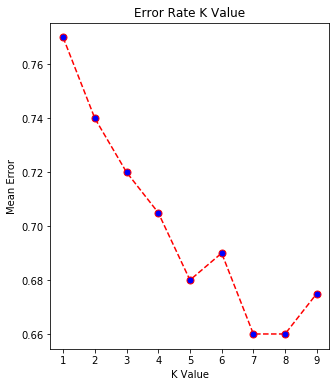

In [14]:
plt.figure(figsize=(5, 6))    #5=width and 6=height of the plot    
plt.plot(range(1, 10), error, color='red', linestyle='dashed', marker='o',
         markerfacecolor='blue', markersize=7)    
plt.title('Error Rate K Value')    #title of the plot
plt.xlabel('K Value')    #labelling x-axis
plt.ylabel('Mean Error')    #labelling y-axis

From the output we can see that the mean error is minimum when the value of the K is 7 and 8.